# 사고 빈도 모델링 4주차: 회귀 성능 지표 (MAE · MSE · RMSE · R²)

> `사고빈도_모델링_음이항GLM.ipynb`에 이어지는 노트북. 0~3단계(전처리·분리)는 같은 코드를 그대로 쓰고, 4주차 과제를 새로 진행함

| 4주차 과제 | 이 노트북에서 하는 일 |
|---|---|
| 1. MAE · MSE · RMSE · R² 값 확인 | LinearRegression(과제 알고리즘)과 지난 주 포아송·음이항 GLM, 기준 모델 2개의 지표 비교 + 시각화 |
| 2. 이상치 유무에 따른 지표 비교 | 원본 칼럼에서 이상치 확인 → 칼럼마다 이상치를 그대로 둔 모델과 비교 → 이상치를 직접 넣어서 지표 변화 확인 |
| 3. 어떤 지표 조합으로 볼지 결정 | 1·2번 결과를 근거로 RMSE · MAE · R² 조합을 정함 |

In [1]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 그래프 한글 폰트: Colab은 `!pip install koreanize-matplotlib` 후 실행, Windows·Mac은 기본 폰트 사용
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    plt.rcParams["font.family"] = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "DejaVu Sans")
plt.rcParams["axes.unicode_minus"] = False   # 음수 부호(-) 깨짐 방지

In [2]:
# ================================================================ 0단계: 불러오기 + 고정 규칙 전처리 (지난 노트북과 같음)
freq = pd.read_csv("freMTPL2freq.csv")
print(f"계약 수: {len(freq):,} · 사고 {freq.ClaimNb.sum():,}건 · "
      f"1년당 사고율 {freq.ClaimNb.sum() / freq.Exposure.sum():.4f}")

# 묶음 번호 (3단계 분할용): 특성 8개가 모두 같은 행 = 같은 계약
FEAT = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand",
        "VehGas", "Density", "Region"]
freq["GroupID"] = freq.groupby(FEAT, sort=False).ngroup()

# [4주차 추가] 2단계 이상치 비교용: 상한 처리(clip) 전 원본 값을 따로 보관
freq_raw = freq.copy()

# 타깃 · 가입 기간: 사고 5건 이상은 4로, 1년 넘는 가입 기간은 1로 상한 처리
freq["ClaimNb"] = freq["ClaimNb"].clip(upper=4)
freq["Exposure"] = freq["Exposure"].clip(upper=1)

# 피처
freq = freq.drop(columns=["Area"])                     # Area는 Density를 6구간으로 자른 것 → 중복
AGE_BINS = [17, 21, 25, 30, 40, 50, 60, 70, 80, 101]
freq["VehAge"] = freq["VehAge"].clip(upper=20)
freq["BonusMalus"] = freq["BonusMalus"].clip(upper=150)
freq["DrivAgeBin"] = pd.cut(freq["DrivAge"], bins=AGE_BINS).astype(str)
freq["VehPower"] = freq["VehPower"].clip(upper=12).astype(str)
freq["logDensity"] = np.log(freq["Density"])

assert freq["Exposure"].between(0, 1, inclusive="right").all(), "Exposure가 0 이하 또는 1 초과"
assert "nan" not in set(freq["DrivAgeBin"]), "나이 구간에 안 들어간 운전자 있음"
print("[0] 고정 규칙 전처리 완료")

계약 수: 678,013 · 사고 36,102건 · 1년당 사고율 0.1007


[0] 고정 규칙 전처리 완료


In [3]:
# ================================================================ 1단계: 전처리 + 모델 설계 (지난 노트북과 같음 + LinearRegression 추가)
NUM_COLS = ["VehAge", "BonusMalus", "logDensity"]                      # 연속형 피처
CAT_COLS = ["DrivAgeBin", "VehPower", "VehGas", "VehBrand", "Region"]  # 범주형 피처


class RareLevelMerger(BaseEstimator, TransformerMixin):
    """사고 수가 min_claims 미만인 범주를 Other로 합침 (fit은 train에서만)"""

    def __init__(self, cols=("Region", "VehBrand"), min_claims=200):
        self.cols = cols
        self.min_claims = min_claims

    def fit(self, X, y):
        claims = pd.Series(np.asarray(y), index=X.index)
        self.keep_ = {}
        for c in self.cols:
            total = claims.groupby(X[c]).sum()
            self.keep_[c] = set(total[total >= self.min_claims].index)
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.cols:
            X[c] = X[c].where(X[c].isin(self.keep_[c]), "Other")
        return X


class SMPoissonGLM(BaseEstimator, RegressorMixin):
    """statsmodels 포아송 GLM을 sklearn 모양으로 감싼 것 (Exposure → offset = log(가입 기간))"""

    def __init__(self, alpha=0.0):
        self.alpha = alpha

    def _split(self, X):
        X = pd.DataFrame(X).copy()
        exposure = X.pop("Exposure") if "Exposure" in X else X.pop(X.columns[-1])
        return sm.add_constant(X, has_constant="add"), np.log(np.asarray(exposure, dtype=float))

    def fit(self, X, y):
        exog, offset = self._split(X)
        model = sm.GLM(np.asarray(y, dtype=float), exog, family=sm.families.Poisson(), offset=offset)
        self.result_ = model.fit()
        self.params_ = np.asarray(self.result_.params)
        return self

    def predict(self, X):
        exog, offset = self._split(X)
        return np.exp(exog.to_numpy(dtype=float) @ self.params_ + offset)


class SMNegBinGLM(SMPoissonGLM):
    """음이항 GLM: 분산 = 평균 + nb_alpha × 평균² (지난 노트북 6단계에서 고른 nb_alpha = 0.84)"""

    def __init__(self, nb_alpha=0.84):
        self.nb_alpha = nb_alpha

    def fit(self, X, y):
        exog, offset = self._split(X)
        family = sm.families.NegativeBinomial(alpha=self.nb_alpha)
        self.result_ = sm.GLM(np.asarray(y, dtype=float), exog, family=family, offset=offset).fit()
        self.params_ = np.asarray(self.result_.params)
        return self


def make_model(estimator):
    # 희귀 범주 합치기 → 숫자는 표준화 · 범주는 원-핫 · Exposure는 그대로 통과(offset) → GLM
    encode = ColumnTransformer([
        ("num", StandardScaler(), NUM_COLS),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
        ("offset", "passthrough", ["Exposure"]),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    return Pipeline([("rare", RareLevelMerger()), ("encode", encode), ("model", estimator)])


def make_linear_model(num_cols=NUM_COLS):
    # [4주차 추가] 과제 알고리즘 LinearRegression
    # LinearRegression은 offset을 받지 못함 → Exposure를 일반 숫자 피처로 넣고 같이 표준화
    # num_cols를 바꿀 수 있게 해서 2단계에서 "이상치를 그대로 둔 칼럼"으로 바꿔 끼움
    encode = ColumnTransformer([
        ("num", StandardScaler(), list(num_cols) + ["Exposure"]),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])
    return Pipeline([("rare", RareLevelMerger()), ("encode", encode), ("model", LinearRegression())])


print("[1] 스케일링 대상:", NUM_COLS, "· 원-핫 대상:", CAT_COLS)

[1] 스케일링 대상: ['VehAge', 'BonusMalus', 'logDensity'] · 원-핫 대상: ['DrivAgeBin', 'VehPower', 'VehGas', 'VehBrand', 'Region']


In [4]:
# ================================================================ 2~3단계: X, Y 추출 + 묶음 단위 분리 (지난 노트북과 같음)
X = freq[["Exposure"] + NUM_COLS + CAT_COLS].copy()
y = freq["ClaimNb"].copy()
groups = freq["GroupID"].copy()

group_claim = freq.groupby("GroupID")["ClaimNb"].max().clip(upper=1)
g_train, g_test = train_test_split(group_claim.index, test_size=0.2, random_state=42,
                                   stratify=group_claim)
is_train = groups.isin(g_train)

X_train, X_test = X[is_train].copy(), X[~is_train].copy()
y_train, y_test = y[is_train].copy(), y[~is_train].copy()
assert set(groups[is_train]).isdisjoint(groups[~is_train]), "같은 묶음이 train과 test에 모두 있음"
print(f"[2~3] X {X.shape[0]:,}행 × {X.shape[1]}열 · train {len(X_train):,} / test {len(X_test):,}")

[2~3] X 678,013행 × 9열 · train 542,576 / test 135,437


## 과제 1단계: MAE · MSE · RMSE · R² 값 확인

| 지표 | 계산 | 의미 | 좋은 방향 |
|---|---|---|---|
| **MAE** | 평균( \|실제 − 예측\| ) | 전형적인 오차 크기. 단위가 "사고 건수"라 바로 읽힘 | 작을수록 |
| **MSE** | 평균( (실제 − 예측)² ) | 오차를 제곱해서 평균. 큰 오차에 벌점이 커짐 | 작을수록 |
| **RMSE** | √MSE | MSE를 원래 단위(건)로 되돌린 값. 큰 오차 존재 여부 | 작을수록 |
| **R²** | 1 − (모델 오차² 합 / 평균으로 예측했을 때 오차² 합) | "모두 평균으로 예측"보다 얼마나 나은지 = 설명력 | 1에 가까울수록 |

비교할 모델
- **LinearRegression**: 과제 알고리즘. Exposure를 피처로 넣음
- **포아송 GLM · 음이항 GLM(alpha 0.84)**: 지난 주 모델. Exposure를 offset으로 넣음
- **기준 모델 2개**: "모두 0건으로 예측", "모두 평균(train 평균)으로 예측". 모델이 이보다 나아야 의미가 있음

In [5]:
# ================================================================ 과제 1단계: 지표 계산
def regression_metrics(y_true, pred):
    mse = mean_squared_error(y_true, pred)
    return {"MAE": mean_absolute_error(y_true, pred), "MSE": mse,
            "RMSE": np.sqrt(mse), "R²": r2_score(y_true, pred)}


# 과제 알고리즘 LinearRegression + 지난 주 GLM 2개 학습 (train으로만)
lin = make_linear_model().fit(X_train, y_train)
pois = make_model(SMPoissonGLM()).fit(X_train, y_train)
nb = make_model(SMNegBinGLM(nb_alpha=0.84)).fit(X_train, y_train)

pred_test = {
    "모두 0건으로 예측": np.zeros(len(y_test)),
    "모두 평균으로 예측": np.full(len(y_test), y_train.mean()),
    "LinearRegression": lin.predict(X_test),
    "포아송 GLM": pois.predict(X_test),
    "음이항 GLM": nb.predict(X_test),
}
metrics_test = pd.DataFrame({name: regression_metrics(y_test, p) for name, p in pred_test.items()}).T
print("[1단계] test 지표 (MAE·MSE·RMSE는 작을수록, R²는 클수록 좋음)")
print(metrics_test.round(5).to_string())

# LinearRegression은 train과 test 지표가 비슷한지(과적합 여부)도 확인
lin_train = regression_metrics(y_train, lin.predict(X_train))
print("\n    LinearRegression train:", {k: round(v, 5) for k, v in lin_train.items()})
print(f"    LinearRegression 음수 예측(사고 건수 < 0): {(pred_test['LinearRegression'] < 0).sum():,}건")

[1단계] test 지표 (MAE·MSE·RMSE는 작을수록, R²는 클수록 좋음)
                      MAE      MSE     RMSE       R²
모두 0건으로 예측        0.05350  0.05998  0.24492 -0.05011
모두 평균으로 예측        0.10124  0.05712  0.23900 -0.00000
LinearRegression  0.10026  0.05639  0.23746  0.01284
포아송 GLM           0.09908  0.05659  0.23789  0.00928
음이항 GLM           0.09957  0.05663  0.23796  0.00866



    LinearRegression train: {'MAE': 0.09977, 'MSE': 0.05573, 'RMSE': np.float64(0.23607), 'R²': 0.01357}
    LinearRegression 음수 예측(사고 건수 < 0): 2,587건


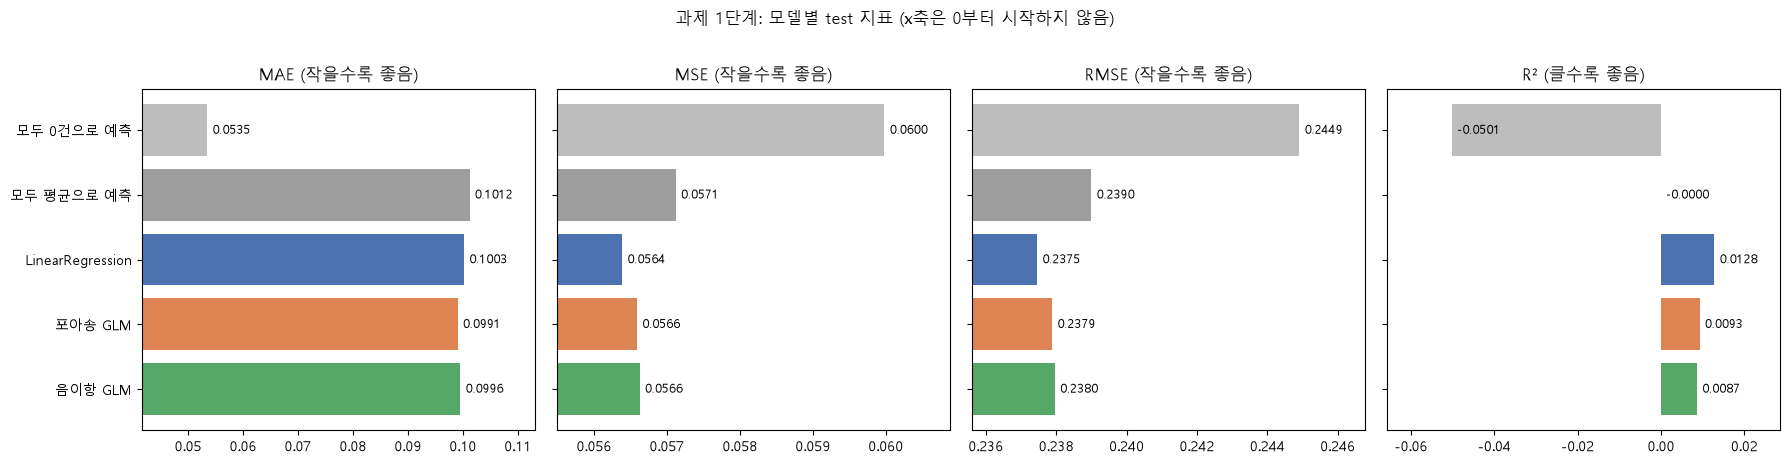

In [6]:
# ---------------------------------------------------------------- 과제 1단계 시각화 ①: 모델별 지표 막대그래프
models = list(metrics_test.index)
colors = ["#bdbdbd", "#9e9e9e", "#4c72b0", "#dd8452", "#55a868"]   # 기준 모델은 회색
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, metric in zip(axes, ["MAE", "MSE", "RMSE", "R²"]):
    values = metrics_test[metric]
    ax.barh(models, values, color=colors)
    ax.set_title(metric + (" (클수록 좋음)" if metric == "R²" else " (작을수록 좋음)"))
    lo, hi = values.min(), values.max()
    pad = (hi - lo) * 0.25 if hi > lo else abs(hi) * 0.1
    ax.set_xlim(lo - pad, hi + pad)                                  # 차이가 작아서 0부터 그리지 않음
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=9)
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("과제 1단계: 모델별 test 지표 (x축은 0부터 시작하지 않음)", y=1.02)
plt.tight_layout()
plt.show()

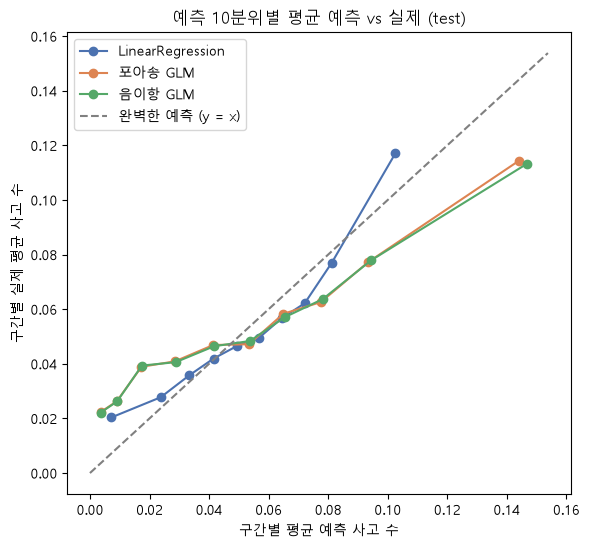

In [7]:
# ---------------------------------------------------------------- 과제 1단계 시각화 ②: 예측 10분위별 평균 예측 vs 실제
# 예측값 순으로 10개 구간으로 나눠, 구간마다 "평균 예측 사고 수"와 "실제 평균 사고 수"를 비교
# 대각선(y = x)에 가까울수록 평균을 잘 맞춘 모델
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, color in zip(["LinearRegression", "포아송 GLM", "음이항 GLM"], colors[2:]):
    p = pred_test[name]
    decile = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    calib = pd.DataFrame({"pred": p, "actual": y_test.to_numpy(), "decile": decile}).groupby("decile").mean()
    ax.plot(calib["pred"], calib["actual"], marker="o", label=name, color=color)
lim = [0, max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lim, lim, ls="--", color="gray", label="완벽한 예측 (y = x)")
ax.set_xlabel("구간별 평균 예측 사고 수")
ax.set_ylabel("구간별 실제 평균 사고 수")
ax.set_title("예측 10분위별 평균 예측 vs 실제 (test)")
ax.legend()
plt.show()

### 과제 1단계 해석

| 모델 (test) | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| 모두 0건으로 예측 | **0.0535** | 0.0600 | 0.2449 | -0.0501 |
| 모두 평균으로 예측 | 0.1012 | 0.0571 | 0.2390 | 0.0000 |
| LinearRegression | 0.1003 | **0.0564** | **0.2375** | **0.0128** |
| 포아송 GLM | 0.0991 | 0.0566 | 0.2379 | 0.0093 |
| 음이항 GLM | 0.0996 | 0.0566 | 0.2380 | 0.0087 |

- **MAE만 보면 "모두 0건으로 예측"이 1등이다.** 계약의 95%가 사고 0건이라, 무조건 0이라고 답해도 평균 오차가 0.0535건밖에 안 된다. MAE는 중앙값(여기서는 0)을 맞힐 때 가장 작아지는 지표라서, 0이 대부분인 건수 데이터에서는 MAE 하나로 모델을 고르면 안 된다.
- **MSE · RMSE · R²로는 LinearRegression이 가장 좋다** (RMSE 0.2375, R² 0.0128). 포아송·음이항 GLM이 바로 뒤를 따르고, 셋 다 "모두 평균으로 예측"(R² 0)보다 낫다.
- **하지만 LinearRegression은 사고 건수를 음수로 예측한 계약이 2,587건**이다. 지표는 좋아도 "사고 -0.02건"처럼 말이 안 되는 값이 나온다.
- LinearRegression의 R²가 GLM보다 높은 이유는 그래프 ②에서 보인다. GLM은 가입 기간을 offset(가입 기간에 정비례)으로 넣어서 예측이 큰 구간에서 실제보다 높게 예측하는데, LinearRegression은 가입 기간을 일반 피처로 넣어 이 비례 가정에 묶이지 않는다.
- LinearRegression의 train RMSE 0.2361 / test 0.2375로 거의 같아서 과적합은 없다.
- R²가 0.01 수준으로 낮은 건 정상이다. 사고는 우연의 영향이 커서 계약 하나하나를 맞히기는 원래 어렵다.

## 과제 2단계: 이상치 유무에 따른 지표 비교

0단계 전처리에서 이미 이상치를 상한 처리(clip)했기 때문에, 원본 값(`freq_raw`)으로 돌아가서 비교함

1. **이상치 확인**: 원본 칼럼에서 IQR 기준(Q3 + 1.5 × IQR 초과)으로 이상치 개수를 세고 상자 그림으로 확인
2. **칼럼별 비교**: 한 칼럼씩 "이상치를 그대로 둔" LinearRegression을 학습해서, 전부 처리한 기준 모델과 test 지표를 비교
3. **직접 넣어 보기**: test 정답에 극단적인 사고 건수를 일부러 넣어서 MAE · RMSE · R²가 각각 얼마나 흔들리는지 확인

In [8]:
# ================================================================ 과제 2단계 ①: 원본 칼럼의 이상치 확인 (IQR 기준)
check_cols = {"ClaimNb": "4건으로 상한", "Exposure": "1년으로 상한", "VehAge": "20년으로 상한",
              "BonusMalus": "150으로 상한", "Density": "log 변환", "DrivAge": "나이 구간으로 묶음"}
rows = []
for col, how in check_cols.items():
    s = freq_raw[col]
    q1, q3 = s.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    n_out = int((s > upper).sum())
    rows.append({"칼럼": col, "Q1": q1, "Q3": q3, "이상치 기준(초과)": upper, "최댓값": s.max(),
                 "이상치 수": n_out, "비율(%)": round(n_out / len(s) * 100, 2), "0단계 처리": how})
outlier_table = pd.DataFrame(rows).set_index("칼럼")
print("[2단계 ①] 원본 칼럼 IQR 이상치")
print(outlier_table.to_string())
print("\n※ ClaimNb는 Q1 = Q3 = 0이라 IQR이 0 → 사고가 1건만 있어도 '이상치'로 잡힘."
      "\n  0이 대부분인 건수 데이터에는 IQR 기준이 맞지 않아서, 기록 오류로 보이는 5건 이상만 상한 처리함")

[2단계 ①] 원본 칼럼 IQR 이상치
               Q1       Q3  이상치 기준(초과)       최댓값  이상치 수  비율(%)      0단계 처리
칼럼                                                                        
ClaimNb      0.00     0.00       0.000     16.00  34060   5.02     4건으로 상한
Exposure     0.18     0.99       2.205      2.01      0   0.00     1년으로 상한
VehAge       2.00    11.00      24.500    100.00   3114   0.46    20년으로 상한
BonusMalus  50.00    64.00      85.000    230.00  62384   9.20    150으로 상한
Density     92.00  1658.00    4007.000  27000.00  77566  11.44      log 변환
DrivAge     34.00    55.00      86.500    100.00   1275   0.19  나이 구간으로 묶음

※ ClaimNb는 Q1 = Q3 = 0이라 IQR이 0 → 사고가 1건만 있어도 '이상치'로 잡힘.
  0이 대부분인 건수 데이터에는 IQR 기준이 맞지 않아서, 기록 오류로 보이는 5건 이상만 상한 처리함


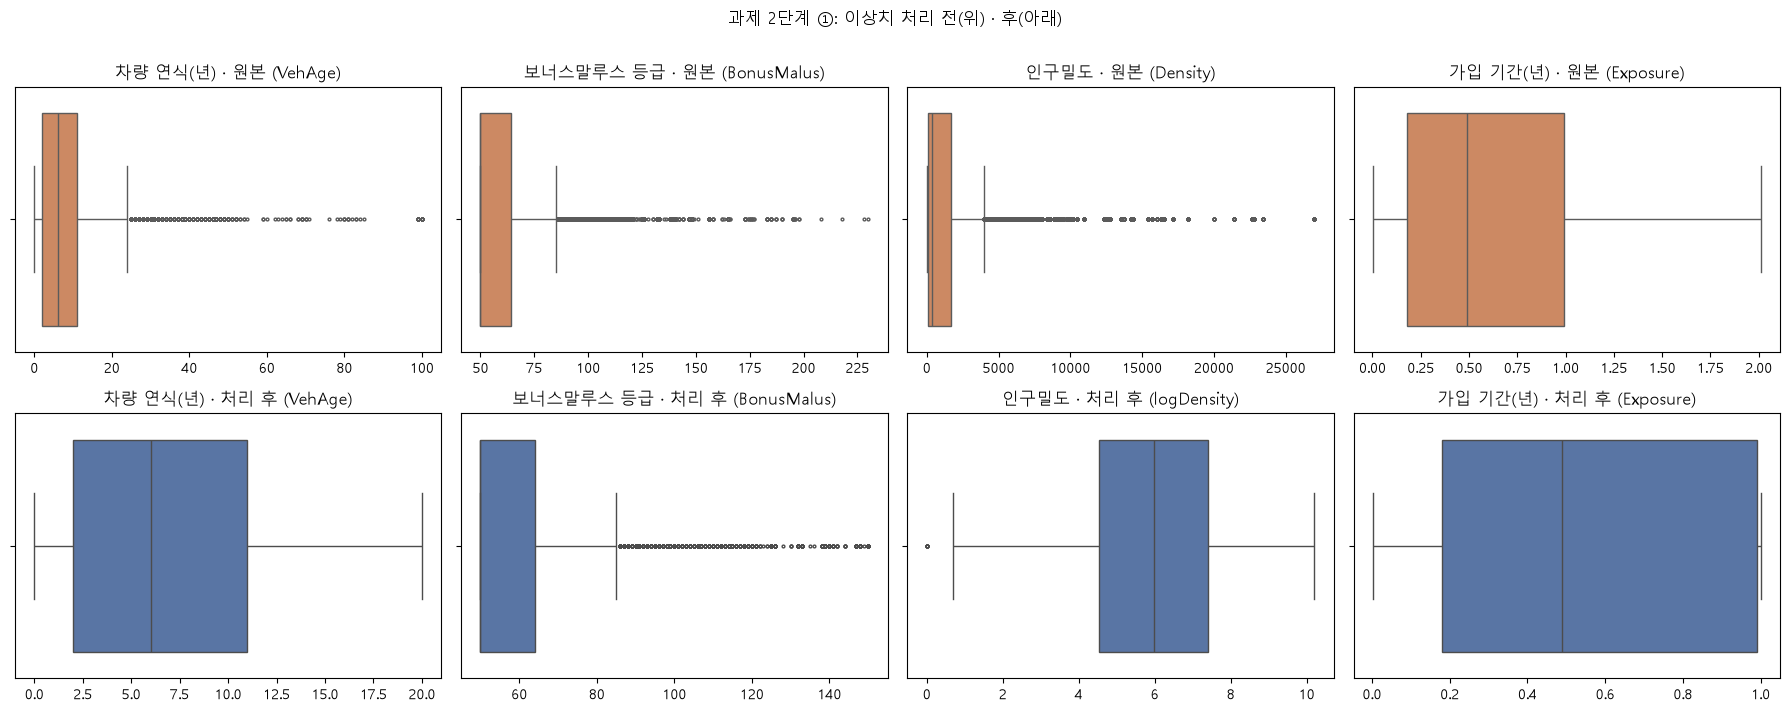

In [9]:
# ---------------------------------------------------------------- 과제 2단계 ① 시각화: 원본 vs 처리 후 상자 그림
pairs = [("VehAge", "VehAge", "차량 연식(년)"), ("BonusMalus", "BonusMalus", "보너스말루스 등급"),
         ("Density", "logDensity", "인구밀도"), ("Exposure", "Exposure", "가입 기간(년)")]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, (raw_col, prep_col, label) in enumerate(pairs):
    sns.boxplot(x=freq_raw[raw_col], ax=axes[0, j], color="#dd8452", fliersize=2)
    axes[0, j].set_title(f"{label} · 원본 ({raw_col})")
    sns.boxplot(x=freq[prep_col], ax=axes[1, j], color="#4c72b0", fliersize=2)
    axes[1, j].set_title(f"{label} · 처리 후 ({prep_col})")
    for i in range(2):
        axes[i, j].set_xlabel("")
fig.suptitle("과제 2단계 ①: 이상치 처리 전(위) · 후(아래)", y=1.01)
plt.tight_layout()
plt.show()

In [10]:
# ================================================================ 과제 2단계 ②: 칼럼마다 이상치를 그대로 둔 모델과 비교
# 기준: 0단계처럼 전부 처리한 LinearRegression (1단계의 lin)
# 변형: 한 칼럼만 원본 값으로 되돌려서 다시 학습 (나머지는 그대로)
# 평가: test는 두 가지 정답으로 계산
#   - "처리된 정답": 1단계와 같은 ClaimNb(4건 상한)
#   - "원본 정답": 상한 처리 전 실제 기록 (타깃 이상치가 지표에 주는 영향 확인용)
raw = freq_raw.loc[X.index]
y_test_raw = raw.loc[~is_train, "ClaimNb"]
print(f"test에서 원본 사고 건수가 4건을 넘는 계약: {(y_test_raw > 4).sum()}개 "
      f"(최댓값 {y_test_raw.max()}건)")


def run_variant(feature_raw=(), target_raw=False):
    """feature_raw에 적은 칼럼만 원본 값으로 되돌려 LinearRegression 학습 → test 지표"""
    Xv = X.copy()
    num_cols = list(NUM_COLS)
    for col in feature_raw:
        if col == "Density":                       # log 변환 전 원본 인구밀도로 교체
            Xv["Density"] = raw["Density"]
            num_cols[num_cols.index("logDensity")] = "Density"
        else:
            Xv[col] = raw[col]
    yv_train = raw.loc[is_train, "ClaimNb"] if target_raw else y_train
    model = make_linear_model(num_cols).fit(Xv[is_train], yv_train)
    p = model.predict(Xv[~is_train])
    return {**{f"{k} (처리된 정답)": v for k, v in regression_metrics(y_test, p).items()},
            **{f"{k} (원본 정답)": v for k, v in regression_metrics(y_test_raw, p).items()}}


variants = {
    "기준: 전부 처리": {},
    "VehAge 이상치 유지": {"feature_raw": ["VehAge"]},
    "BonusMalus 이상치 유지": {"feature_raw": ["BonusMalus"]},
    "Density 원본(log 안 함)": {"feature_raw": ["Density"]},
    "Exposure 이상치 유지": {"feature_raw": ["Exposure"]},
    "ClaimNb(타깃) 이상치 유지": {"target_raw": True},
    "전부 원본": {"feature_raw": ["VehAge", "BonusMalus", "Density", "Exposure"], "target_raw": True},
}
outlier_result = pd.DataFrame({name: run_variant(**kw) for name, kw in variants.items()}).T
show = ["MAE (처리된 정답)", "RMSE (처리된 정답)", "R² (처리된 정답)", "RMSE (원본 정답)", "R² (원본 정답)"]
print("\n[2단계 ②] 이상치 유무에 따른 LinearRegression test 지표")
print(outlier_result[show].round(5).to_string())

test에서 원본 사고 건수가 4건을 넘는 계약: 5개 (최댓값 16건)



[2단계 ②] 이상치 유무에 따른 LinearRegression test 지표
                     MAE (처리된 정답)  RMSE (처리된 정답)  R² (처리된 정답)  RMSE (원본 정답)  R² (원본 정답)
기준: 전부 처리                 0.10026        0.23746      0.01284       0.24332     0.01198
VehAge 이상치 유지             0.10028        0.23747      0.01276       0.24333     0.01192
BonusMalus 이상치 유지         0.10026        0.23747      0.01281       0.24332     0.01196
Density 원본(log 안 함)       0.10026        0.23749      0.01263       0.24335     0.01178
Exposure 이상치 유지           0.10026        0.23747      0.01281       0.24332     0.01196
ClaimNb(타깃) 이상치 유지        0.10029        0.23746      0.01284       0.24332     0.01199
전부 원본                     0.10032        0.23750      0.01251       0.24336     0.01167


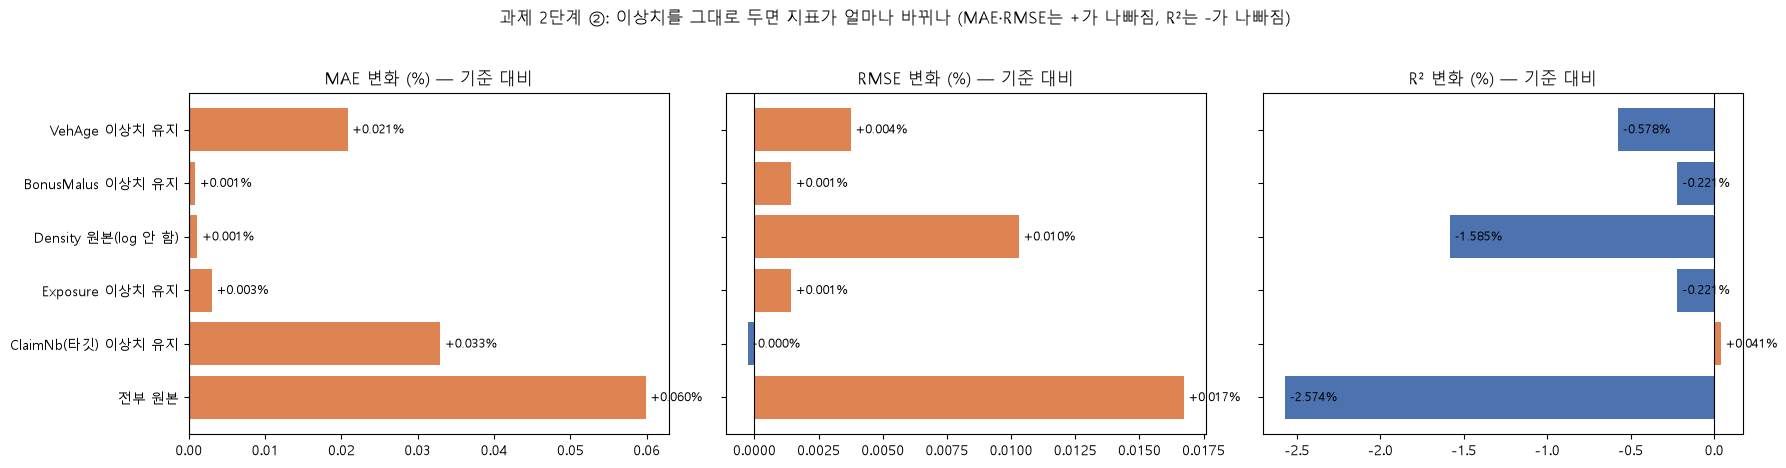

In [11]:
# ---------------------------------------------------------------- 과제 2단계 ② 시각화: 기준 대비 지표 변화(%)
base = outlier_result.loc["기준: 전부 처리"]
change = (outlier_result.drop(index="기준: 전부 처리") / base - 1) * 100
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["MAE (처리된 정답)", "RMSE (처리된 정답)", "R² (처리된 정답)"]):
    values = change[metric]
    ax.barh(values.index, values, color=["#dd8452" if v > 0 else "#4c72b0" for v in values])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{metric.split(' ')[0]} 변화 (%) — 기준 대비")
    for i, v in enumerate(values):
        ax.text(v, i, f" {v:+.3f}%", va="center", fontsize=9)
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("과제 2단계 ②: 이상치를 그대로 두면 지표가 얼마나 바뀌나 (MAE·RMSE는 +가 나빠짐, R²는 -가 나빠짐)", y=1.03)
plt.tight_layout()
plt.show()

[2단계 ③] 사고 10건짜리 이상치를 test에 넣었을 때 (test 135,437개 중)
              MAE      MSE     RMSE       R²
넣은 이상치 수                                    
0         0.10026  0.05639  0.23746  0.01284
1         0.10033  0.05713  0.23901  0.01254
5         0.10062  0.06003  0.24502  0.01206
10        0.10099  0.06370  0.25238  0.01130
50        0.10387  0.09285  0.30471  0.00784
100       0.10755  0.12942  0.35975  0.00523

    이상치 0개 대비 변화(%)
          MAE    MSE  RMSE    R²
넣은 이상치 수                        
0         0.0    0.0   0.0   0.0
1         0.1    1.3   0.7  -2.3
5         0.4    6.5   3.2  -6.1
10        0.7   13.0   6.3 -12.0
50        3.6   64.7  28.3 -38.9
100       7.3  129.5  51.5 -59.3


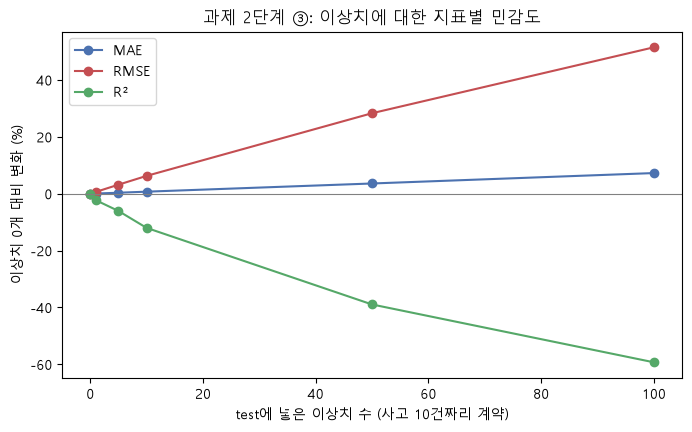

In [12]:
# ================================================================ 과제 2단계 ③: test 정답에 이상치를 직접 넣어 보기
# 모델(1단계 lin)은 그대로 두고, test 계약 중 일부의 사고 건수를 10건으로 바꿈
# → 같은 예측값인데 정답에 극단값이 섞이면 각 지표가 얼마나 흔들리는지 확인
rng = np.random.default_rng(0)
p_lin = pred_test["LinearRegression"]
inject_rows = []
for k in [0, 1, 5, 10, 50, 100]:
    y_inj = y_test.to_numpy().copy()
    idx = rng.choice(len(y_inj), size=k, replace=False)
    y_inj[idx] = 10                                            # 극단적인 사고 건수 10건
    inject_rows.append({"넣은 이상치 수": k, **regression_metrics(y_inj, p_lin)})
inject = pd.DataFrame(inject_rows).set_index("넣은 이상치 수")
inject_change = (inject / inject.loc[0] - 1) * 100
print("[2단계 ③] 사고 10건짜리 이상치를 test에 넣었을 때 (test 135,437개 중)")
print(inject.round(5).to_string())
print("\n    이상치 0개 대비 변화(%)")
print(inject_change.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
for metric, color in zip(["MAE", "RMSE", "R²"], ["#4c72b0", "#c44e52", "#55a868"]):
    ax.plot(inject_change.index, inject_change[metric], marker="o", label=metric, color=color)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("test에 넣은 이상치 수 (사고 10건짜리 계약)")
ax.set_ylabel("이상치 0개 대비 변화 (%)")
ax.set_title("과제 2단계 ③: 이상치에 대한 지표별 민감도")
ax.legend()
plt.show()

### 과제 2단계 해석

**① 원본 칼럼의 이상치 (IQR 기준)**

| 칼럼 | 이상치 수 (비율) | 최댓값 | 0단계 처리 |
|---|---|---|---|
| Density | 77,566개 (11.44%) | 27,000 | log 변환 |
| BonusMalus | 62,384개 (9.20%) | 230 | 150으로 상한 |
| VehAge | 3,114개 (0.46%) | 100 | 20으로 상한 |
| DrivAge | 1,275개 (0.19%) | 100 | 나이 구간으로 묶음 |
| Exposure | 0개 (IQR 기준) | 2.01 | 1년으로 상한 (1년 초과 1,224건은 기록 오차) |
| ClaimNb | IQR 사용 불가 | 16 | 4건으로 상한 (5건 이상 9건) |

**② 피처의 이상치는 지표를 거의 바꾸지 않았다**
- 한 칼럼씩 원본으로 되돌려도 MAE·RMSE 변화는 모두 0.06% 이하였다.
- 가장 영향이 큰 건 Density를 log 변환하지 않은 경우로 R²가 1.6% 낮아졌고(0.01284 → 0.01263), 전부 원본이면 R²가 2.6% 낮아졌다. 처리하는 편이 조금이라도 낫다.
- 영향이 작은 이유: 학습 데이터가 54만 개라 극단값 몇 개가 계수를 크게 흔들지 못하고, 표준화로 크기도 맞춰져 있기 때문이다.

**③ 정답(타깃)의 이상치는 지표를 크게 흔든다**
- 같은 모델인데 test 정답만 원본(사고 5건 이상 그대로)으로 바꾸면 RMSE가 0.2375 → 0.2433(+2.5%)으로 나빠진다. test 135,437개 중 단 **5개**(최대 16건) 때문이다.
- 사고 10건짜리 이상치를 test에 직접 넣어 보면 차이가 분명하다.

| 넣은 이상치 수 | MAE 변화 | RMSE 변화 | R² 변화 |
|---|---|---|---|
| 10개 (0.007%) | +0.7% | +6.3% | -12.0% |
| 100개 (0.07%) | +7.3% | +51.5% | -59.3% |

- **MAE는 이상치에 강하고, RMSE와 R²는 아주 민감하다.** 슬라이드의 설명처럼 MAE는 "전형적인 오차 크기", RMSE는 "큰 오차가 있는지"를 보여준다.
- 그래서 정답의 기록 오류(사고 5건 이상)를 4건으로 상한 처리한 0단계 결정이 RMSE·R²를 믿을 수 있게 만드는 데 중요하다.

## 과제 3단계: 어떤 지표 조합으로 볼지 결정

**결정: RMSE(주 지표) + R²(설명력) + MAE(보조) — 건수 데이터 참고용으로 Poisson deviance 함께**

| 지표 | 이번 데이터에서 확인한 것 | 역할 |
|---|---|---|
| **RMSE** | 평균을 잘 맞힌 모델이 낮게 나옴. 큰 오차(다건 사고)에 민감 (이상치 100개에 +51.5%) | **주 지표.** 보험료는 "평균 사고 수"로 정하므로 평균을 맞히는 능력이 가장 중요. 단, 타깃 이상치는 상한 처리한 뒤 사용 |
| **R²** | "모두 평균" 대비 개선 정도 (LinearRegression 0.0128) | **설명력.** 모델끼리 비교할 때 사용. 값이 작은 건 사고가 우연의 영향이 큰 문제라서 |
| **MAE** | 이상치에 강함(+7.3%)이지만 "모두 0건 예측"이 가장 좋게 나옴 | **보조.** 전형적인 오차 크기를 건 단위로 설명할 때만 쓰고, 반드시 "모두 0건 예측" 기준과 함께 봄 |
| MSE | RMSE와 같은 정보, 단위가 건² | 보고하지 않음 (RMSE로 대신) |
| Poisson deviance | 건수 데이터 전용 지표. "모두 0건 예측"을 1.38로 가장 나쁘게 평가 | 참고 (지난 주 주 지표) |

- 이 조합으로 보면 **LinearRegression이 RMSE·R²는 가장 좋지만 음수 예측이 2,587건**이고, **포아송·음이항 GLM은 지표가 거의 같으면서 예측이 항상 0 이상**이다.
- 따라서 지표 조합은 슬라이드 예시처럼 "RMSE · MAE로 실제 오차 크기 + R²로 설명력"으로 정하되, 이 데이터에서는 MAE를 단독으로 쓰지 않는다는 조건을 붙인다.

In [13]:
# ================================================================ 과제 3단계: 최종 지표 조합으로 정리
final_cols = ["RMSE", "R²", "MAE"]
final = metrics_test[final_cols].copy()
final["Poisson deviance (참고)"] = [mean_poisson_deviance(y_test, np.clip(p, 1e-6, None)) for p in pred_test.values()]
print("[3단계] 최종 지표 조합: RMSE(주) + R²(설명력) + MAE(보조)  ·  건수 데이터 참고용 Poisson deviance")
print(final.round(5).to_string())

[3단계] 최종 지표 조합: RMSE(주) + R²(설명력) + MAE(보조)  ·  건수 데이터 참고용 Poisson deviance
                     RMSE       R²      MAE  Poisson deviance (참고)
모두 0건으로 예측        0.24492 -0.05011  0.05350                1.37982
모두 평균으로 예측        0.23900 -0.00000  0.10124                0.32185
LinearRegression  0.23746  0.01284  0.10026                0.31621
포아송 GLM           0.23789  0.00928  0.09908                0.32087
음이항 GLM           0.23796  0.00866  0.09957                0.32087
